In [3]:
import json
import os
import sys
import random
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.metrics.pairwise import cosine_similarity
import torch
from sentence_transformers import SentenceTransformer

# ---- Project path setup ----
_PROJECT_ROOT = Path.cwd().parents[2]
if str(_PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(_PROJECT_ROOT))
    
from sparqlce.embedder import SPARQLEmbedder

# Academic plotting theme
sns.set_theme(style="ticks", context="paper", font_scale=1.4)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print(f"✓ Project root set to: {_PROJECT_ROOT}")

✓ Project root set to: /local/upb/users/z/zahera/profiles/unix/cs/SPARQL-Embeddings


In [4]:
# Seed sampling so Figure 3 is reproducible across machines/runs
random.seed(42)
np.random.seed(42)

import time
import requests
from pathlib import Path

# ====================================================================
# 1. Path Setup
# ====================================================================
_PROJECT_ROOT = Path.cwd().parents[2]

# Pointing to the Wikidata files based on your logs
TRIPLETS_PATH = os.path.join(_PROJECT_ROOT, "datasets", "wikidata_testset_RQ1.json") 
RESULTS_PATH = os.path.join(_PROJECT_ROOT, "datasets", "result_sets_wikidata.json")

# Wikidata SPARQL Endpoint (in case you ever need to re-run the queries)
SPARQL_ENDPOINT = "https://query.wikidata.org/sparql"

print(f"Project root set to: {_PROJECT_ROOT}")

# ====================================================================
# 2. Load the Local Data & Extract Queries
# ====================================================================
print(f"Loading triplets from {TRIPLETS_PATH}...")
with open(TRIPLETS_PATH, "r", encoding="utf-8") as f:
    triplets_data = json.load(f)

anchors = [item.get("query", item.get("anchor_query", "")).strip() for item in triplets_data]

corpus_set = set()
for item in triplets_data:
    q = item.get("query", item.get("anchor_query", "")).strip()
    if q: corpus_set.add(q)
    for p in item.get("positive_queries", []):
        corpus_set.add(p["query"].strip() if isinstance(p, dict) else p.strip())
    for n in item.get("negative_queries", []):
        corpus_set.add(n["query"].strip() if isinstance(n, dict) else n.strip())

corpus_queries = list(corpus_set)
print(f"Found {len(corpus_queries)} unique queries in the test set corpus.")

# ====================================================================
# 3. Execute Queries & Save to JSON (Skipped if file exists)
# ====================================================================
def execute_sparql(query, retries=3):
    """Executes a SPARQL query and returns a list of canonical stringified rows."""
    headers = {
        "Accept": "application/sparql-results+json",
        "User-Agent": "SPARQL-Evaluation-Script/1.0" # Wikidata requires a user agent
    }
    for attempt in range(retries):
        try:
            response = requests.get(SPARQL_ENDPOINT, params={"query": query}, headers=headers, timeout=45)
            if response.status_code == 200:
                data = response.json()
                results = []
                for binding in data.get("results", {}).get("bindings", []):
                    row_str = json.dumps(binding, sort_keys=True)
                    results.append(row_str)
                return results
            else:
                print(f"  [Attempt {attempt+1}] Failed with status {response.status_code}")
                time.sleep(2)
        except Exception as e:
            print(f"  [Attempt {attempt+1}] Exception: {e}")
            time.sleep(2)
    return [] 

if not os.path.exists(RESULTS_PATH):
    print(f"\nResult file not found. Executing {len(corpus_queries)} queries against Wikidata...")
    query_results = {}
    
    for i, q in enumerate(corpus_queries):
        if i % 10 == 0:
            print(f"Executing query {i}/{len(corpus_queries)}...")
            
        res = execute_sparql(q)
        query_results[q] = res
        time.sleep(0.5) # Polite delay for Wikidata

    with open(RESULTS_PATH, "w", encoding="utf-8") as f:
        json.dump(query_results, f, ensure_ascii=False, indent=2)
    print(f"✓ Saved {len(query_results)} query results to {RESULTS_PATH}")
else:
    print(f"\n{RESULTS_PATH} already exists. Skipping execution phase.")

# ====================================================================
# 4. Load the Cached Results
# ====================================================================
print(f"Loading cached Wikidata results from {RESULTS_PATH}...")
with open(RESULTS_PATH, "r", encoding="utf-8") as f:
    query_results = json.load(f)

print(f"✓ Successfully loaded {len(query_results)} cached query results!")

# ====================================================================
# 5. Stratified Sampling (Optimized Fast Jaccard)
# ====================================================================
def build_viz1_pairs(anchors, corpus_queries, result_sets, k_per_anchor=30):
    pairs = []
    
    # Pre-convert JSON lists to sets and filter out queries that returned 0 results
    cached_sets = {q: set(res) for q, res in result_sets.items() if res}
    
    valid_anchors = [a for a in anchors if a in cached_sets]
    valid_corpus = [c for c in corpus_queries if c in cached_sets]
    
    total_anchors = len(valid_anchors)
    print(f"Executing stratified sampling for {total_anchors} valid anchors...")
    
    for idx, a in enumerate(valid_anchors):
        # Progress indicator so you know it hasn't frozen
        if idx % 10 == 0:
            print(f"  -> Processing anchor {idx}/{total_anchors}...")
            
        Ra = cached_sets[a]
        jaccards = []
        
        for c in valid_corpus:
            if c == a: continue
            Rc = cached_sets[c]
            
            # FAST JACCARD CALCULATION (Avoids costly set | operator)
            intersection_len = len(Ra & Rc)
            
            # EXTRA OPTIMIZATION: If no overlap, Jaccard is 0. Skip the math.
            if intersection_len == 0:
                jaccards.append((c, 0.0))
                continue
                
            union_len = len(Ra) + len(Rc) - intersection_len
            
            if union_len == 0: continue
                
            j = intersection_len / union_len
            jaccards.append((c, j))

        # Stratified sample across Jaccard bins
        bins = {i: [] for i in range(5)}
        for c, j in jaccards:
            b = min(int(j * 5), 4)
            bins[b].append((c, j))
            
        sampled = []
        per_bin = max(1, k_per_anchor // 5)
        for b in bins.values():
            sampled.extend(random.sample(b, min(per_bin, len(b))))

        for c, j in sampled:
            pairs.append((a, c, j))
            
    return pairs

sampled_pairs = build_viz1_pairs(anchors, corpus_queries, query_results, k_per_anchor=30)
print(f"✓ Stratified sampling complete! Generated {len(sampled_pairs)} pairs for plotting.")

Project root set to: /local/upb/users/z/zahera/profiles/unix/cs/SPARQL-Embeddings
Loading triplets from /local/upb/users/z/zahera/profiles/unix/cs/SPARQL-Embeddings/datasets/wikidata_testset_RQ1.json...
Found 2229 unique queries in the test set corpus.

/local/upb/users/z/zahera/profiles/unix/cs/SPARQL-Embeddings/datasets/result_sets_wikidata.json already exists. Skipping execution phase.
Loading cached Wikidata results from /local/upb/users/z/zahera/profiles/unix/cs/SPARQL-Embeddings/datasets/result_sets_wikidata.json...
✓ Successfully loaded 2229 cached query results!
Executing stratified sampling for 186 valid anchors...
  -> Processing anchor 0/186...
  -> Processing anchor 10/186...
  -> Processing anchor 20/186...
  -> Processing anchor 30/186...
  -> Processing anchor 40/186...
  -> Processing anchor 50/186...
  -> Processing anchor 60/186...
  -> Processing anchor 70/186...
  -> Processing anchor 80/186...
  -> Processing anchor 90/186...
  -> Processing anchor 100/186...
  -> 

In [5]:
# ====================================================================
# 3. Initialize Models & Encode Corpus
# ====================================================================
import numpy as np
import torch
from sentence_transformers import SentenceTransformer

# --- NEW: Restored Missing Variables ---
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SPARQLCE_CKPT = os.path.join(_PROJECT_ROOT, "sparqlce", "models", "wikidata_model_mrr_0.3238.pt")

print(f"Using device: {DEVICE}")

# Define wrappers
class HFEncoder:
    def __init__(self, model_name, prefix=''):
        self.model = SentenceTransformer(model_name, device=DEVICE)
        self.prefix = prefix
    def encode(self, queries):
        texts = [f"{self.prefix}{q}" for q in queries]
        return self.model.encode(texts, convert_to_numpy=True, show_progress_bar=False, normalize_embeddings=True)

class SparqlCEEncoderWrap:
    def __init__(self, ckpt):
        self.embedder = SPARQLEmbedder(ckpt)
    def encode(self, queries):
        # SPARQLEmbedder already normalizes inside our previous patches
        embs = self.embedder.encode(queries)
        if not isinstance(embs, np.ndarray): embs = np.array(embs)
        return embs

# Dictionary of requested models
models = {
    'SparqlCE': SparqlCEEncoderWrap(SPARQLCE_CKPT),
    'MiniLM': HFEncoder('sentence-transformers/all-MiniLM-L6-v2'),
    'MPNet': HFEncoder('sentence-transformers/all-mpnet-base-v2'),
    'E5-base': HFEncoder('intfloat/e5-base-v2', prefix='query: '),
    'Qwen3': HFEncoder('Qwen/Qwen3-Embedding-0.6B') 
}

# Encode the unique queries that appear in our sampled pairs
unique_needed_queries = list(set([p[0] for p in sampled_pairs] + [p[1] for p in sampled_pairs]))
model_embeddings = {}

print(f"Encoding {len(unique_needed_queries)} unique queries...")
for name, encoder in models.items():
    print(f" -> Encoding with {name}...")
    embs = encoder.encode(unique_needed_queries)
    model_embeddings[name] = {q: embs[i] for i, q in enumerate(unique_needed_queries)}
    
print("✓ All models encoded.")

Using device: cuda
Loading model from /local/upb/users/z/zahera/profiles/unix/cs/SPARQL-Embeddings/sparqlce/models/wikidata_model_mrr_0.3238.pt...
Encoding 1029 unique queries...
 -> Encoding with SparqlCE...
 -> Encoding with MiniLM...
 -> Encoding with MPNet...
 -> Encoding with E5-base...
 -> Encoding with Qwen3...
✓ All models encoded.


In [ ]:
# ====================================================================
# 4. Build Plotting DataFrame & Generate Hexbin Plot (paper-ready)
# ====================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# --- 1. Build the DataFrame ---
plot_data = []
for anchor, cand, j_score in sampled_pairs:
    row = {'anchor': anchor, 'candidate': cand, 'jaccard': j_score}
    for name in models.keys():
        v1 = model_embeddings[name][anchor]
        v2 = model_embeddings[name][cand]
        # Since embeddings are L2 normalized, dot product == cosine similarity
        row[name] = np.clip(np.dot(v1, v2), -1.0, 1.0)
    plot_data.append(row)

df = pd.DataFrame(plot_data)

# --- 2. Print-ready hexbin panel ---
# Sized for a full-width figure* (~7in wide): fonts keep their point size in
# print instead of being shrunk 2.5x as with the previous 19.5in canvas.
fig, axes = plt.subplots(1, 5, figsize=(7.2, 1.95), sharey=True)

plot_config = [
    ("SparqlCE", "Blues"),   # ours, highlighted
    ("MiniLM",   "Greys"),
    ("MPNet",    "Greys"),
    ("E5-base",  "Greys"),
    ("Qwen3",    "Greys"),
]

# Draw all hexbins first, then unify the density scale across panels so the
# single colorbar is valid for EVERY panel (same lightness == same count).
# NOTE: with bins="log", matplotlib >= 3.6 keeps raw counts and a LogNorm,
# while older versions store log10(count) with a linear norm - handle both.
from matplotlib.colors import LogNorm

hb_objects = []
for ax, (name, cmap) in zip(axes, plot_config):
    hb = ax.hexbin(df['jaccard'].values, df[name].values,
                   gridsize=30, cmap=cmap, mincnt=1, bins="log")
    hb_objects.append(hb)

vmax = max(float(hb.get_array().max()) for hb in hb_objects)
uses_lognorm = isinstance(hb_objects[0].norm, LogNorm)
for hb in hb_objects:
    hb.set_clim(1.0 if uses_lognorm else 0.0, vmax)

for ax, (name, cmap) in zip(axes, plot_config):
    j = df['jaccard'].values
    c = df[name].values
    rho, _ = spearmanr(j, c)

    ax.plot([0, 1], [0, 1], color="#d62728", linestyle="--",
            linewidth=1.0, zorder=10)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
    ax.set_title(name, fontsize=8, fontweight="bold", pad=3)
    ax.set_xlabel("Jaccard", fontsize=7)
    ax.set_xticks([0, 0.5, 1.0])
    ax.set_yticks([0, 0.5, 1.0])
    ax.tick_params(labelsize=6, length=2)
    ax.text(0.05, 0.95, fr"$\rho={rho:.2f}$", transform=ax.transAxes,
            fontsize=7, fontweight="bold", va="top",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1.5))
    ax.grid(True, linestyle=":", alpha=0.3, linewidth=0.4)

axes[0].set_ylabel("Cosine similarity", fontsize=7)

# One colorbar, valid for all panels after the shared clim above. Rendered in
# the neutral (Greys) scale; the SparqlCE panel uses the same count scale in blue.
cb = fig.colorbar(hb_objects[1], ax=axes.tolist(), shrink=0.85, pad=0.012, aspect=18)
cb.set_label("pair count (log scale)" if uses_lognorm
             else r"$\log_{10}$(pair count)", fontsize=6.5)
cb.ax.tick_params(labelsize=6)

output_pdf_path = os.path.join(_PROJECT_ROOT, "results", "cosine_vs_jaccard_wikidata.pdf")
os.makedirs(os.path.dirname(output_pdf_path), exist_ok=True)
plt.savefig(output_pdf_path, bbox_inches="tight")

print(f"Print-ready hexbin plot saved to: {output_pdf_path}")
plt.show()


In [7]:
import numpy as np
j_arr = np.array([p[2] for p in sampled_pairs])
print(f"Total pairs: {len(j_arr)}")
print(f"  Jaccard = 0.0 exactly:       {(j_arr == 0.0).sum()}")
print(f"  Jaccard in (0.0, 0.2):        {((j_arr > 0) & (j_arr < 0.2)).sum()}")
print(f"  Jaccard in [0.2, 0.4):        {((j_arr >= 0.2) & (j_arr < 0.4)).sum()}")
print(f"  Jaccard in [0.4, 0.6):        {((j_arr >= 0.4) & (j_arr < 0.6)).sum()}")
print(f"  Jaccard in [0.6, 0.8):        {((j_arr >= 0.6) & (j_arr < 0.8)).sum()}")
print(f"  Jaccard in [0.8, 1.0):        {((j_arr >= 0.8) & (j_arr < 1.0)).sum()}")
print(f"  Jaccard = 1.0 exactly:       {(j_arr == 1.0).sum()}")

Total pairs: 2126
  Jaccard = 0.0 exactly:       1115
  Jaccard in (0.0, 0.2):        1
  Jaccard in [0.2, 0.4):        3
  Jaccard in [0.4, 0.6):        50
  Jaccard in [0.6, 0.8):        2
  Jaccard in [0.8, 1.0):        2
  Jaccard = 1.0 exactly:       953


Plotting 2068 pairs (1115 disjoint, 953 identical)


/tmp/ipykernel_352098/2488364048.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_352098/2488364048.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_352098/2488364048.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_352098/2488364048.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_352098/2488364048.py:

✓ Saved to /local/upb/users/z/zahera/profiles/unix/cs/SPARQL-Embeddings/results/cosine_vs_jaccard_rq1_wikidata.pdf


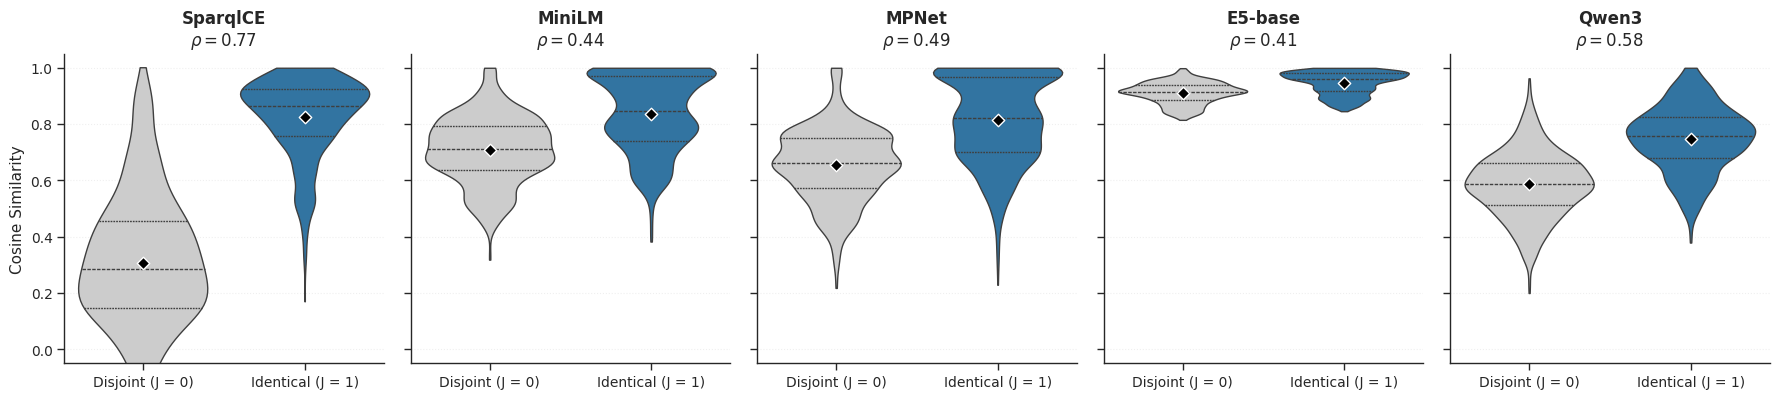

Mean cosine per bucket:
Model        Disjoint  Identical      Gap
SparqlCE        0.307      0.823    0.517
MiniLM          0.709      0.837    0.129
MPNet           0.656      0.815    0.159
E5-base         0.911      0.945    0.035
Qwen3           0.586      0.749    0.163


In [11]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# Bucket the pairs. Drop the noisy middle 2.7% from the plot.
df_plot = df.copy()
df_plot = df_plot[(df_plot["jaccard"] == 0.0) | (df_plot["jaccard"] == 1.0)]
df_plot["bucket"] = df_plot["jaccard"].map(
    {0.0: "Disjoint (J = 0)", 1.0: "Identical (J = 1)"}
)
print(f"Plotting {len(df_plot)} pairs ({(df_plot['bucket']=='Disjoint (J = 0)').sum()} disjoint, "
      f"{(df_plot['bucket']=='Identical (J = 1)').sum()} identical)")

PLOT_MODELS = ["SparqlCE", "MiniLM", "MPNet", "E5-base", "Qwen3"]
PALETTE = {"Disjoint (J = 0)": "#cccccc", "Identical (J = 1)": "#1f77b4"}

fig, axes = plt.subplots(1, 5, figsize=(18, 4.2), sharey=True)

for ax, name in zip(axes, PLOT_MODELS):
    # Use full df (including middle) for the correlation; plot only the buckets
    rho, _ = spearmanr(df["jaccard"], df[name])

    sns.violinplot(
        data=df_plot, x="bucket", y=name, ax=ax,
        palette=PALETTE, inner="quartile", cut=0, linewidth=1.0,
    )

    # Annotate the means as horizontal markers
    means = df_plot.groupby("bucket")[name].mean()
    for i, b in enumerate(["Disjoint (J = 0)", "Identical (J = 1)"]):
        ax.scatter(i, means[b], marker="D", s=40,
                   color="black", zorder=10, edgecolor="white", linewidth=1.0)

    # Title with Spearman ρ
    ax.set_title(f"{name}\n" + fr"$\rho = {rho:.2f}$",
                 fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylim(-0.05, 1.05)
    ax.tick_params(labelsize=10)
    ax.grid(True, axis="y", linestyle=":", alpha=0.3)

axes[0].set_ylabel("Cosine Similarity", fontsize=11)

plt.tight_layout()
output_pdf = os.path.join(_PROJECT_ROOT, "results", "cosine_vs_jaccard_rq1_wikidata.pdf")
plt.savefig(output_pdf, dpi=300, bbox_inches="tight")
print(f"✓ Saved to {output_pdf}")
plt.show()

print("Mean cosine per bucket:")
print(f"{'Model':10s} {'Disjoint':>10s} {'Identical':>10s} {'Gap':>8s}")
for name in PLOT_MODELS:
    md = df_plot[df_plot['bucket']=='Disjoint (J = 0)'][name].mean()
    mi = df_plot[df_plot['bucket']=='Identical (J = 1)'][name].mean()
    print(f"{name:10s} {md:>10.3f} {mi:>10.3f} {mi-md:>8.3f}")
